In [1]:
import os
from google.colab import drive
drive.mount("/content/drive")

PROJ = "/content/drive/MyDrive/il2_mimetic"
assert os.path.isfile(f"{PROJ}/stage1_motif/params.json"), \
    f"project not found at {PROJ} — wrong Drive account mounted?"
print(sorted(os.listdir(PROJ)))

Mounted at /content/drive
['2B5I.pdb', 'analysis_tm', 'controls', 'stage1_motif', 'stage2_backbones', 'stage3_seqs', 'stage4_fold', 'stage5_complex']


In [2]:
import os, glob, subprocess, textwrap
import numpy as np, pandas as pd

PROJ = "/content/drive/MyDrive/il2_mimetic"
OUT3, OUT4 = f"{PROJ}/stage3_seqs", f"{PROJ}/stage4_fold"
OUTA = f"{PROJ}/analysis_msa"; os.makedirs(OUTA, exist_ok=True)

subprocess.run(["pip","-q","install","pydssp","biopython"], check=True)
subprocess.run(["apt-get","-qq","install","-y","mafft"], check=True)

import pydssp
from Bio import SeqIO, AlignIO
from Bio.PDB import PDBParser, PPBuilder

parser, ppb = PDBParser(QUIET=True), PPBuilder()

def chain_seq(path, chain_id="A"):
    st = parser.get_structure("x", path)
    ch = st[0][chain_id]
    return "".join(str(pp.get_sequence()) for pp in ppb.build_peptides(ch))

def chain_ss(path, chain_id=None):
    """H/E/- per residue via pydssp. Writes a single-chain temp file first."""
    st = parser.get_structure("x", path)
    ch = st[0][chain_id] if chain_id else next(iter(st[0]))
    tmp = "/content/_ss_tmp.pdb"
    with open(tmp, "w") as fh:
        for res in ch:
            if not all(a in res for a in ("N","CA","C","O")): continue
            for an in ("N","CA","C","O"):
                a = res[an]; x, y, z = a.coord
                fh.write(f"ATOM  {a.serial_number:5d} {an:^4s}{res.resname:>4s} A"
                         f"{res.id[1]:4d}    {x:8.3f}{y:8.3f}{z:8.3f}\n")
    coords = pydssp.read_pdbtext(open(tmp).read())
    return "".join(pydssp.assign(coords, out_type="c3"))

# ---- rows: 6 diverse candidates + two references ----
div = pd.read_csv(f"{OUT4}/stage5_candidates_diverse.tsv", sep="\t")
seqs = pd.read_csv(f"{OUT3}/sequences.tsv", sep="\t")
cs = div.merge(seqs[["seq_id","sequence"]], on="seq_id")
print(f"{len(cs)} candidates")

records, ss_map = [], {}
for _, r in cs.iterrows():
    records.append((r.seq_id, r.sequence))
    pdb = f"{OUT4}/pdb/{r.seq_id}.pdb"
    ss_map[r.seq_id] = chain_ss(pdb) if os.path.exists(pdb) else None

neo = f"{OUT3}/benchmark/6DG6.pdb"
il2 = f"{PROJ}/2B5I.pdb"
import json
CHAIN = json.load(open(f"{PROJ}/stage1_motif/params.json"))["chains"]
records.append(("Neo-2_15", chain_seq(neo, "A")))
records.append(("IL-2",     chain_seq(il2, CHAIN["IL2"])))

with open(f"{OUTA}/rows.fasta","w") as fh:
    for name, s in records:
        fh.write(f">{name}\n{s}\n")

# ---- MAFFT ----
res = subprocess.run(["mafft","--quiet","--maxiterate","1000","--localpair",
                      f"{OUTA}/rows.fasta"], capture_output=True, text=True)
open(f"{OUTA}/aligned.fasta","w").write(res.stdout)
aln = AlignIO.read(f"{OUTA}/aligned.fasta","fasta")
print(f"alignment: {len(aln)} rows x {aln.get_alignment_length()} columns")

# ---- project each candidate's SS onto alignment columns ----
ss_aligned = {}
for rec in aln:
    ss = ss_map.get(rec.id)
    if ss is None: continue
    out, k = [], 0
    for c in str(rec.seq):
        if c == "-": out.append(" ")
        else:
            out.append(ss[k] if k < len(ss) else " "); k += 1
    ss_aligned[rec.id] = "".join(out)

# consensus SS: the majority assignment among candidates, where >=2/3 agree
L = aln.get_alignment_length()
cons = []
for i in range(L):
    col = [v[i] for v in ss_aligned.values() if v[i] != " "]
    if not col: cons.append(" "); continue
    top = max(set(col), key=col.count)
    cons.append(top if col.count(top) >= (2*len(col)/3) else "-")
CONS_SS = "".join(cons)

# columns invariant across the candidates (not gaps)
cand_ids = set(cs.seq_id)
rows_c = [str(r.seq) for r in aln if r.id in cand_ids]
invariant = [i for i in range(L)
             if len({r[i] for r in rows_c}) == 1 and rows_c[0][i] != "-"]

print(f"consensus SS : {CONS_SS.count('H')} H, {CONS_SS.count('E')} E columns")
print(f"invariant across candidates: {len(invariant)} columns")

np.save(f"{OUTA}/invariant_cols.npy", np.array(invariant))
open(f"{OUTA}/consensus_ss.txt","w").write(CONS_SS)

6 candidates
alignment: 8 rows x 159 columns
consensus SS : 106 H, 0 E columns
invariant across candidates: 27 columns


159

wrote /content/drive/MyDrive/il2_mimetic/figures/alignment_properties.png


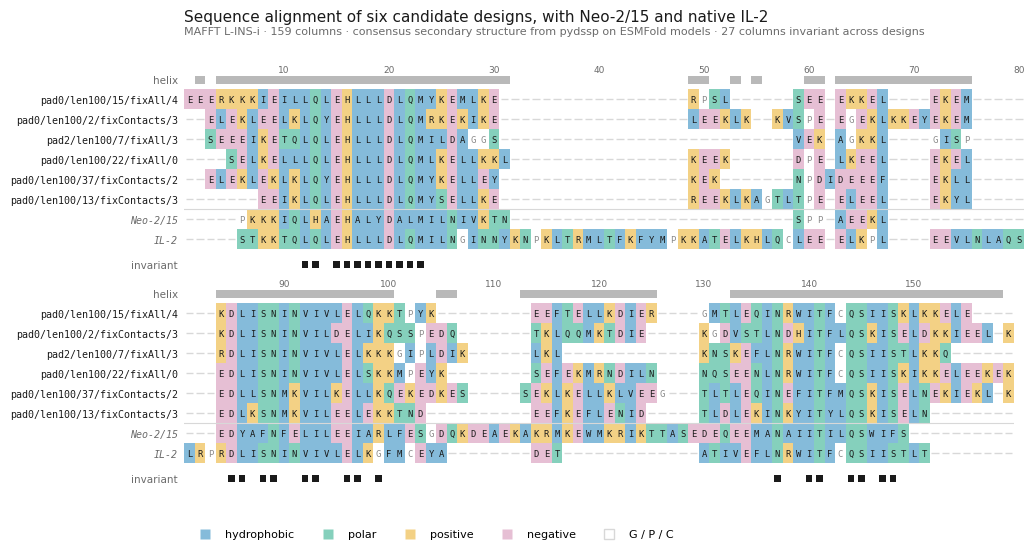

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

FIG = f"{PROJ}/figures"; os.makedirs(FIG, exist_ok=True)

CLASSES = {
    "hydrophobic": ("#0072B2", set("AVLIMFWY")),
    "polar":       ("#009E73", set("STNQ")),
    "positive":    ("#E69F00", set("KRH")),
    "negative":    ("#CC79A7", set("DE")),
}
OTHER_INK = "#8a8a8a"                      # G, P, C — uncoloured, letter only
def cls_of(a):
    for name, (hexc, members) in CLASSES.items():
        if a in members: return hexc
    return None

rows   = [(r.id, str(r.seq)) for r in aln]
L      = len(rows[0][1])
inv    = set(invariant)
PER    = 80                                 # columns per block
blocks = [(i, min(i+PER, L)) for i in range(0, L, PER)]

CW, RH = 0.105, 0.19                        # cell width / row height, inches
fig_w  = 1.55 + PER*CW
fig_h  = sum(len(rows)*RH + 0.62 for _ in blocks) + 1.35
fig = plt.figure(figsize=(fig_w, fig_h))

INK, MUTED, RULE = "#1a1a1a", "#6b6b6b", "#d8d8d8"
y_cursor = 1.0 - 0.70/fig_h

for bi, (s, e) in enumerate(blocks):
    width = e - s
    bh    = len(rows)*RH + 0.62
    y_cursor -= bh / fig_h
    ax = fig.add_axes([1.45/fig_w, y_cursor, width*CW/fig_w, bh/fig_h])
    ax.set_xlim(0, width); ax.set_ylim(-1.5, len(rows)+1.2)
    ax.axis("off")

    # --- consensus secondary structure track ---
    for i in range(s, e):
        if CONS_SS[i] == "H":
            ax.add_patch(Rectangle((i-s, len(rows)+0.25), 1, 0.42,
                                   facecolor="#b9b9b9", edgecolor="none"))
    ax.text(-0.6, len(rows)+0.46, "helix", ha="right", va="center",
            fontsize=7.5, color=MUTED)

    # --- sequence cells ---
    for ri, (name, seq) in enumerate(rows):
        y = len(rows) - 1 - ri
        for i in range(s, e):
            a = seq[i]
            if a == "-":
                ax.plot([i-s+0.15, i-s+0.85], [y+0.5, y+0.5],
                        color=RULE, lw=1.0, solid_capstyle="butt")
                continue
            c = cls_of(a)
            if c:
                ax.add_patch(Rectangle((i-s, y), 1, 1, facecolor=c,
                                       alpha=0.48, edgecolor="none"))
            ax.text(i-s+0.5, y+0.46, a, ha="center", va="center",
                    fontsize=6.4, family="monospace",
                    color=INK if c else OTHER_INK)

    # --- invariant-column ticks ---
    for i in range(s, e):
        if i in inv:
            ax.add_patch(Rectangle((i-s+0.18, -0.95), 0.64, 0.34,
                                   facecolor="#1a1a1a", edgecolor="none"))
    ax.text(-0.6, -0.78, "invariant", ha="right", va="center",
            fontsize=7.5, color=MUTED)

    # --- row labels + reference separator ---
    for ri, (name, _) in enumerate(rows):
        y = len(rows) - 1 - ri
        is_ref = name in ("Neo-2_15", "IL-2")
        ax.text(-0.6, y+0.46, name.replace("_", "/"), ha="right", va="center",
                fontsize=7.2, family="monospace",
                color=MUTED if is_ref else INK,
                style="italic" if is_ref else "normal")
    n_des = len(rows) - 2
    ax.plot([-0.4, width], [len(rows)-n_des]*2, color=RULE, lw=0.8)

    # column numbering every 10
    for i in range(s, e):
        if (i+1) % 10 == 0:
            ax.text(i-s+0.5, len(rows)+0.95, str(i+1), ha="center",
                    va="center", fontsize=6.5, color=MUTED)

# --- legend + title ---
handles = [Line2D([0],[0], marker="s", linestyle="none", markersize=7,
                  markerfacecolor=c, markeredgecolor="none", alpha=0.48, label=n)
           for n, (c, _) in CLASSES.items()]
handles.append(Line2D([0],[0], marker="s", linestyle="none", markersize=7,
                      markerfacecolor="white", markeredgecolor=RULE,
                      label="G / P / C"))
fig.legend(handles=handles, loc="lower left", ncol=5, frameon=False,
           fontsize=8, bbox_to_anchor=(1.45/fig_w, 0.015))

fig.text(1.45/fig_w, 0.975,
         "Sequence alignment of six candidate designs, with Neo-2/15 and native IL-2",
         fontsize=11, color=INK, va="top")
fig.text(1.45/fig_w, 0.945,
         f"MAFFT L-INS-i · {L} columns · consensus secondary structure from "
         f"pydssp on ESMFold models · {len(inv)} columns invariant across designs",
         fontsize=8, color=MUTED, va="top")

for ext in ("png","pdf"):
    fig.savefig(f"{FIG}/alignment_properties.{ext}", dpi=300, bbox_inches="tight")
print("wrote", f"{FIG}/alignment_properties.png")
plt.show()

In [5]:
from Bio.Align import PairwiseAligner, substitution_matrices
al = PairwiseAligner(mode="global")
al.substitution_matrix = substitution_matrices.load("BLOSUM62")
al.open_gap_score, al.extend_gap_score = -11, -1

def pid(a, b):
    x = al.align(a, b)[0]
    s1, s2 = str(x[0]), str(x[1])
    m = sum(p == q for p, q in zip(s1, s2) if p != "-")
    return 100 * m / min(len(a), len(b))

il2_seq = dict(records)["IL-2"]; neo_seq = dict(records)["Neo-2_15"]
for name, seq in records[:6]:
    print(f"{name:34s}  vs IL-2 {pid(seq, il2_seq):5.1f}%   "
          f"vs Neo {pid(seq, neo_seq):5.1f}%")
print(f"{'Neo-2/15':34s}  vs IL-2 {pid(neo_seq, il2_seq):5.1f}%")

pad0_len100_15_fixAll_4             vs IL-2  49.5%   vs Neo  25.0%
pad0_len100_2_fixContacts_3         vs IL-2  39.1%   vs Neo  32.0%
pad2_len100_7_fixAll_3              vs IL-2  60.4%   vs Neo  30.8%
pad0_len100_22_fixAll_0             vs IL-2  50.5%   vs Neo  27.0%
pad0_len100_37_fixContacts_2        vs IL-2  36.9%   vs Neo  30.0%
pad0_len100_13_fixContacts_3        vs IL-2  39.8%   vs Neo  33.7%
Neo-2/15                            vs IL-2  30.0%


In [6]:
scram = [s for n, s in records if "scram" in n.lower()]
# if the scrambled control isn't in `records`, pull it from the Stage 5 FASTA:
import glob
if not scram:
    f = glob.glob(f"{PROJ}/stage5_complex/inputs/ctrl_scram_alpha.fasta")[0]
    lines = [l.strip() for l in open(f) if l.strip()]
    scram = [lines[1]]
print(f"scrambled design vs IL-2 : {pid(scram[0], il2_seq):5.1f}%")
print(f"scrambled design vs Neo  : {pid(scram[0], neo_seq):5.1f}%")

scrambled design vs IL-2 :  20.0%
scrambled design vs Neo  :  20.0%


In [7]:
import random
random.seed(0)
nulls = []
for name, seq in records[:6]:
    for _ in range(20):
        sh = list(seq); random.shuffle(sh)
        nulls.append(pid("".join(sh), il2_seq))
import numpy as np
nulls = np.array(nulls)
print(f"null identity vs IL-2 (n={len(nulls)}): "
      f"mean {nulls.mean():.1f}%  sd {nulls.std():.1f}  "
      f"95th pct {np.percentile(nulls,95):.1f}%")

null identity vs IL-2 (n=120): mean 22.9%  sd 3.5  95th pct 28.6%


In [8]:
nulls_neo = []
for name, seq in records[:6]:
    for _ in range(20):
        sh = list(seq); random.shuffle(sh)
        nulls_neo.append(pid("".join(sh), neo_seq))
nulls_neo = np.array(nulls_neo)
print(f"null vs Neo: mean {nulls_neo.mean():.1f}%  sd {nulls_neo.std():.1f}  "
      f"95th {np.percentile(nulls_neo,95):.1f}%")

null vs Neo: mean 20.6%  sd 3.1  95th 26.0%


In [9]:
# columns in the alignment belonging to the three frozen segments:
# approximate them as the invariant columns, which cluster on the motif
inv_cols = set(invariant)
rows_d = {r.id: str(r.seq) for r in aln}
neo_a  = rows_d["Neo-2_15"]

def pid_masked(a_id):
    a = rows_d[a_id]
    pairs = [(a[i], neo_a[i]) for i in range(len(a))
             if i not in inv_cols and a[i] != "-" and neo_a[i] != "-"]
    return 100 * sum(p == q for p, q in pairs) / len(pairs)

for name, _ in records[:6]:
    print(f"{name:34s}  vs Neo, motif masked: {pid_masked(name):5.1f}%")

pad0_len100_15_fixAll_4             vs Neo, motif masked:  15.3%
pad0_len100_2_fixContacts_3         vs Neo, motif masked:  18.3%
pad2_len100_7_fixAll_3              vs Neo, motif masked:  18.9%
pad0_len100_22_fixAll_0             vs Neo, motif masked:  14.8%
pad0_len100_37_fixContacts_2        vs Neo, motif masked:  15.6%
pad0_len100_13_fixContacts_3        vs Neo, motif masked:  23.6%


In [10]:
import random
random.seed(0)
null_masked = []
for name, _ in records[:6]:
    a = rows_d[name]
    free = [i for i in range(len(a))
            if i not in inv_cols and a[i] != "-" and neo_a[i] != "-"]
    letters = [a[i] for i in free]
    for _ in range(20):
        sh = letters[:]; random.shuffle(sh)
        null_masked.append(100 * sum(s == neo_a[i] for s, i in zip(sh, free))
                           / len(free))
null_masked = np.array(null_masked)
print(f"matched null (motif masked, n={len(null_masked)}): "
      f"mean {null_masked.mean():.1f}%  sd {null_masked.std():.1f}  "
      f"95th {np.percentile(null_masked,95):.1f}%")

matched null (motif masked, n=120): mean 9.4%  sd 3.7  95th 16.4%


In [11]:
# Checking against other human extracellular proteins, which are not cytokines
import urllib.request, random, numpy as np, subprocess
from Bio import AlignIO

CONTROLS = {"saposinC": ("1M12", "A"), "apoE_Nterm": ("1LE2", "A")}

extra = []
for name, (pdb_id, ch) in CONTROLS.items():
    p = f"{OUTA}/{pdb_id}.pdb"
    urllib.request.urlretrieve(f"https://files.rcsb.org/download/{pdb_id}.pdb", p)
    s = chain_seq(p, ch)
    extra.append((name, s))
    print(f"{name:12s} {pdb_id}  {len(s)} residues")
    print(f"             {s[:60]}...")

# --- realign designs + references + controls together ---
with open(f"{OUTA}/rows_ctrl.fasta", "w") as fh:
    for name, s in records + extra:
        fh.write(f">{name}\n{s}\n")

res = subprocess.run(["mafft","--quiet","--maxiterate","1000","--localpair",
                      f"{OUTA}/rows_ctrl.fasta"], capture_output=True, text=True)
open(f"{OUTA}/aligned_ctrl.fasta","w").write(res.stdout)
a2 = AlignIO.read(f"{OUTA}/aligned_ctrl.fasta","fasta")
R, L2 = {r.id: str(r.seq) for r in a2}, a2.get_alignment_length()

cand_ids = [n for n, _ in records[:6]]
rows_c   = [R[i] for i in cand_ids]
inv2 = {i for i in range(L2)
        if len({r[i] for r in rows_c}) == 1 and rows_c[0][i] != "-"}
print(f"\nrealigned: {L2} columns, {len(inv2)} invariant across designs")

def masked_vs(ref_id, seed=0):
    random.seed(seed)
    obs, null = [], []
    for cid in cand_ids:
        a, b = R[cid], R[ref_id]
        free = [i for i in range(L2)
                if i not in inv2 and a[i] != "-" and b[i] != "-"]
        if len(free) < 20:
            print(f"   ! {cid} vs {ref_id}: only {len(free)} comparable columns")
            continue
        letters = [a[i] for i in free]
        obs.append(100*sum(a[i] == b[i] for i in free)/len(free))
        for _ in range(20):
            sh = letters[:]; random.shuffle(sh)
            null.append(100*sum(s == b[i] for s, i in zip(sh, free))/len(free))
    return np.array(obs), np.array(null)

print(f"\n{'reference':14s} {'observed':>10s} {'null':>14s} {'z':>7s}")
for ref in ["Neo-2_15"] + list(CONTROLS):
    o, n = masked_vs(ref)
    z = (o.mean() - n.mean()) / n.std()
    print(f"{ref:14s} {o.mean():9.1f}% {n.mean():8.1f}±{n.std():.1f} {z:+7.1f}")


saposinC     1M12  84 residues
             SDVYCEVCEFLVKEVTKLIDNNKTEKEILDAFDKMCSKLPKSLSEECQEVVDTYGSSILS...
apoE_Nterm   1LE2  144 residues
             GQRWELALGRFWDYLRWVQTLSEQVQEELLSSQVTQELRALMDETMKELKAYKSELEEQL...

realigned: 190 columns, 27 invariant across designs

reference        observed           null       z
Neo-2_15            18.3%      9.7±3.8    +2.2
saposinC            14.9%      8.3±4.4    +1.5
apoE_Nterm          19.8%      9.1±3.3    +3.2
